# 泰坦尼克号生存预测

这是我第一次做完整的机器学习项目，记录一下整个思考和分析过程。

**问题定义：** 根据乘客的个人信息（年龄、性别、船舱等级等），预测他们在泰坦尼克号沉船事故中是否能生存下来。

**数据来源：** Kaggle Titanic 竞赛数据集

---
**分析步骤：**
1. 数据加载与初步了解
2. 探索性数据分析（EDA）
3. 数据清洗与特征工程
4. 建立机器学习模型
5. 模型对比与调优
6. 生成预测结果

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# ── 暗色主题配置（参考本地样式规范）──────────────────────────────────────
BG      = '#2b2b2b'   # 画布 / 绘图区背景
FG      = 'white'     # 坐标轴文字、刻度
TITLE   = '#f4a261'   # 标题颜色（暖橙）
SPINE   = '#cfcfcf'   # 外框线颜色
GRID_C  = '#888888'   # 网格颜色
FONT    = 'SimHei'    # 中文字体

plt.rcParams['font.sans-serif'] = [FONT, 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False


def dark_ax(ax, title='', xlabel='', ylabel='', grid_axis='both'):
    '''把一个 Axes 统一设成暗色风格'''
    ax.set_facecolor(BG)
    ax.figure.set_facecolor(BG)
    if title:
        ax.set_title(title, fontsize=14, color=TITLE, pad=10)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=12, color=FG)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12, color=FG)
    ax.tick_params(colors=FG, labelsize=11)
    for spine in ax.spines.values():
        spine.set_color(SPINE)
        spine.set_linewidth(1.2)
    if grid_axis:
        ax.grid(True, axis=grid_axis, linestyle='--', alpha=0.3, color=GRID_C)


def save_fig(fig, path):
    fig.savefig(path, dpi=130, bbox_inches='tight', facecolor=BG)


print('库导入完成，暗色主题配置就绪')


库导入完成，暗色主题配置就绪


## 第一步：加载数据

In [2]:
train = pd.read_csv('data/titanic/train.csv')
test  = pd.read_csv('data/titanic/test.csv')

print(f'训练集：{train.shape[0]} 行，{train.shape[1]} 列')
print(f'测试集：{test.shape[0]} 行，{test.shape[1]} 列')
train.head()


训练集：891 行，12 列
测试集：418 行，11 列


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print('=== 训练集基本信息 ===')
train.info()
print()
print('=== 数值列统计摘要 ===')
train.describe()


=== 训练集基本信息 ===
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

=== 数值列统计摘要 ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 第二步：探索性数据分析（EDA）

从宏观角度理解数据，再逐一分析各特征与生存率的关系。

In [4]:
# 缺失值统计
print('=== 训练集缺失值 ===')
miss = train.isnull().sum()
pct  = (miss / len(train) * 100).round(2)
print(pd.DataFrame({'缺失数量': miss, '缺失比例(%)': pct})[miss > 0])

print()
print('=== 测试集缺失值 ===')
miss2 = test.isnull().sum()
pct2  = (miss2 / len(test) * 100).round(2)
print(pd.DataFrame({'缺失数量': miss2, '缺失比例(%)': pct2})[miss2 > 0])


=== 训练集缺失值 ===
          缺失数量  缺失比例(%)
Age        177    19.87
Cabin      687    77.10
Embarked     2     0.22

=== 测试集缺失值 ===
       缺失数量  缺失比例(%)
Age      86    20.57
Fare      1     0.24
Cabin   327    78.23


遇难：549 人 (61.6%)，生还：342 人 (38.4%)


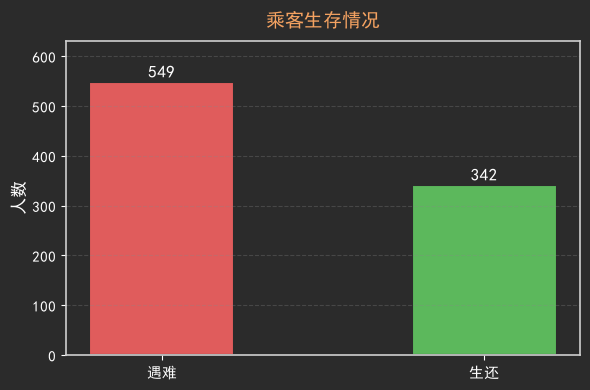

In [5]:
# 图 1：整体生存情况
cnt = train['Survived'].value_counts()
print(f'遇难：{cnt[0]} 人 ({cnt[0]/len(train)*100:.1f}%)，'
      f'生还：{cnt[1]} 人 ({cnt[1]/len(train)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(6, 4), facecolor=BG)
colors = ['#e05c5c', '#5cb85c']
bars = ax.bar(['遇难', '生还'], cnt.values, color=colors, width=0.45,
              edgecolor=BG, linewidth=1.5)
for bar, v in zip(bars, cnt.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 8, str(v),
            ha='center', fontsize=12, color=FG)
dark_ax(ax, title='乘客生存情况', ylabel='人数', grid_axis='y')
ax.set_ylim(0, max(cnt.values) * 1.15)
plt.tight_layout()
save_fig(fig, 'plot_01_survival_overall.png')
plt.show()


各性别生存率： {'female': 0.742, 'male': 0.189}


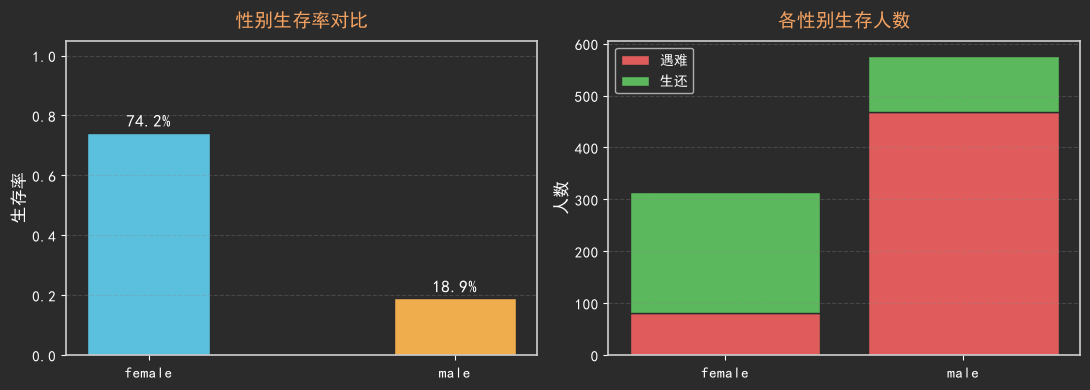

In [6]:
# 图 2：性别与生存率
sex_surv = train.groupby('Sex')['Survived'].mean()
print('各性别生存率：', sex_surv.round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=BG)

# 左：生存率柱状图
bar_colors = ['#5bc0de', '#f0ad4e']
bars = axes[0].bar(sex_surv.index, sex_surv.values,
                   color=bar_colors, width=0.4, edgecolor=BG)
for bar, val in zip(bars, sex_surv.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.02,
                f'{val:.1%}', ha='center', fontsize=12, color=FG)
axes[0].set_ylim(0, 1.05)
dark_ax(axes[0], title='性别生存率对比', ylabel='生存率', grid_axis='y')

# 右：堆叠人数
sex_cnt = train.groupby(['Sex', 'Survived']).size().unstack(fill_value=0)
x = range(len(sex_cnt))
axes[1].bar(x, sex_cnt[0], label='遇难', color='#e05c5c', edgecolor=BG)
axes[1].bar(x, sex_cnt[1], bottom=sex_cnt[0], label='生还',
            color='#5cb85c', edgecolor=BG)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(sex_cnt.index)
leg = axes[1].legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(axes[1], title='各性别生存人数', ylabel='人数', grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_02_sex_survival.png')
plt.show()


各舱等生存率： {1: 0.63, 2: 0.473, 3: 0.242}


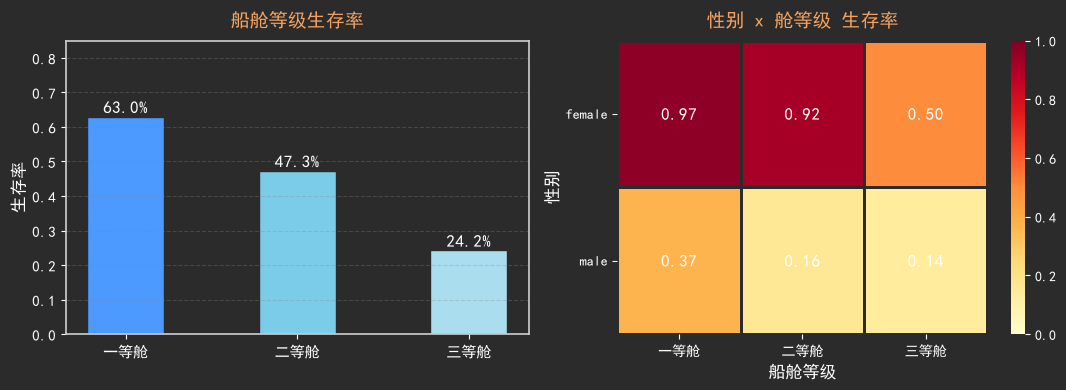

In [7]:
# 图 3：船舱等级与生存率
pc_surv = train.groupby('Pclass')['Survived'].mean()
print('各舱等生存率：', pc_surv.round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=BG)

# 左：生存率
labels  = ['一等舱', '二等舱', '三等舱']
pc_clrs = ['#4C9AFF', '#7BCCE8', '#AADDEE']
bars = axes[0].bar(labels, pc_surv.values, color=pc_clrs,
                   width=0.45, edgecolor=BG)
for bar, val in zip(bars, pc_surv.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.1%}', ha='center', fontsize=12, color=FG)
axes[0].set_ylim(0, 0.85)
dark_ax(axes[0], title='船舱等级生存率', ylabel='生存率', grid_axis='y')

# 右：热力图——性别 x 舱等级
pivot = train.pivot_table(values='Survived', index='Sex',
                          columns='Pclass', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd',
            ax=axes[1], linewidths=1, linecolor=BG,
            vmin=0, vmax=1,
            annot_kws={'color': 'white', 'fontsize': 12})
axes[1].set_xticklabels(['一等舱', '二等舱', '三等舱'], color=FG)
axes[1].set_yticklabels(axes[1].get_yticklabels(), color=FG, rotation=0)
axes[1].set_xlabel('船舱等级', color=FG, fontsize=12)
axes[1].set_ylabel('性别', color=FG, fontsize=12)
axes[1].set_title('性别 x 舱等级 生存率', fontsize=14, color=TITLE, pad=10)
axes[1].tick_params(colors=FG)
axes[1].figure.set_facecolor(BG)
axes[1].set_facecolor(BG)
cbar = axes[1].collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)

plt.tight_layout()
save_fig(fig, 'plot_03_pclass_survival.png')
plt.show()


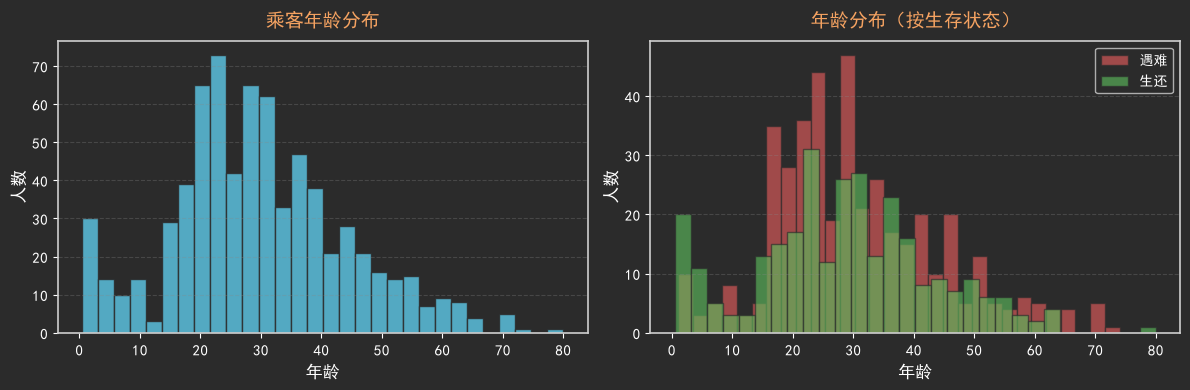

年龄均值：29.7，中位数：28.0


In [8]:
# 图 4：年龄分布（约 20% 缺失，先用现有数据观察规律）
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=BG)

# 整体年龄分布
axes[0].hist(train['Age'].dropna(), bins=30,
             color='#5bc0de', edgecolor=BG, alpha=0.85)
dark_ax(axes[0], title='乘客年龄分布', xlabel='年龄', ylabel='人数', grid_axis='y')

# 按生存状态分开
d0 = train[train['Survived'] == 0]['Age'].dropna()
d1 = train[train['Survived'] == 1]['Age'].dropna()
axes[1].hist(d0, bins=30, alpha=0.65, color='#e05c5c',
             label='遇难', edgecolor=BG)
axes[1].hist(d1, bins=30, alpha=0.65, color='#5cb85c',
             label='生还', edgecolor=BG)
leg = axes[1].legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(axes[1], title='年龄分布（按生存状态）', xlabel='年龄', ylabel='人数',
        grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_04_age_distribution.png')
plt.show()

print(f'年龄均值：{train["Age"].mean():.1f}，中位数：{train["Age"].median():.1f}')


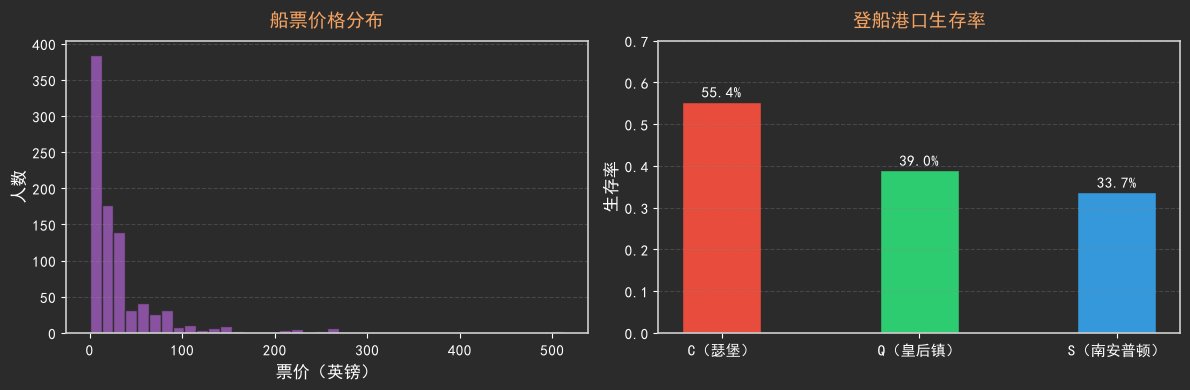

In [9]:
# 图 5：票价分布 & 登船港口生存率
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor=BG)

# 票价分布
axes[0].hist(train['Fare'], bins=40,
             color='#9b59b6', edgecolor=BG, alpha=0.85)
dark_ax(axes[0], title='船票价格分布', xlabel='票价（英镑）', ylabel='人数',
        grid_axis='y')

# 登船港口生存率
emb_surv   = train.groupby('Embarked')['Survived'].mean()
emb_labels = ['C（瑟堡）', 'Q（皇后镇）', 'S（南安普顿）']
emb_clrs   = ['#e74c3c', '#2ecc71', '#3498db']
bars = axes[1].bar(emb_labels, emb_surv.values,
                   color=emb_clrs, width=0.4, edgecolor=BG)
for bar, val in zip(bars, emb_surv.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.01,
                f'{val:.1%}', ha='center', fontsize=11, color=FG)
axes[1].set_ylim(0, 0.7)
dark_ax(axes[1], title='登船港口生存率', ylabel='生存率', grid_axis='y')

plt.tight_layout()
save_fig(fig, 'plot_05_fare_embarked.png')
plt.show()


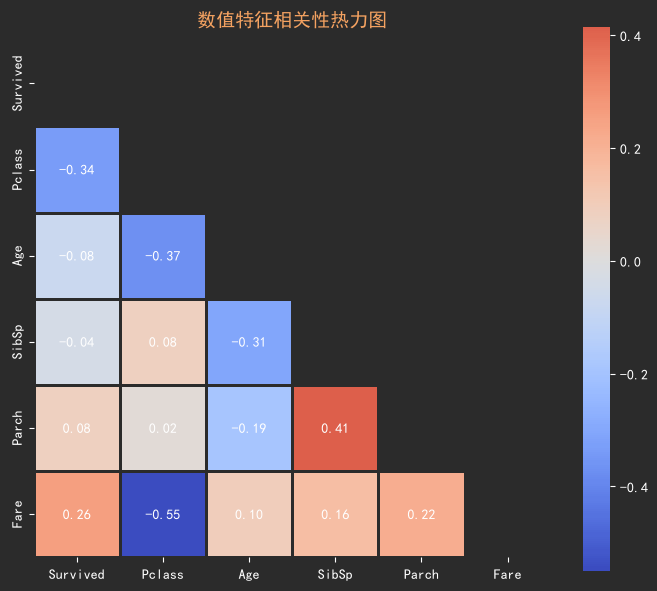

与 Survived 的相关系数（降序）：
Fare      0.257307
Parch     0.081629
SibSp    -0.035322
Age      -0.077221
Pclass   -0.338481
Name: Survived, dtype: float64


In [10]:
# 图 6：数值特征相关性热力图
num_cols    = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr_matrix = train[num_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6), facecolor=BG)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=ax,
            linewidths=1, linecolor=BG, square=True,
            annot_kws={'color': FG, 'fontsize': 10})
ax.set_title('数值特征相关性热力图', fontsize=14, color=TITLE, pad=10)
ax.tick_params(colors=FG, labelsize=10)
ax.set_facecolor(BG)
ax.figure.set_facecolor(BG)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)

plt.tight_layout()
save_fig(fig, 'plot_06_correlation.png')
plt.show()

print('与 Survived 的相关系数（降序）：')
print(corr_matrix['Survived'].sort_values(ascending=False).drop('Survived'))


## 第三步：数据清洗与特征工程

EDA 发现几个需要处理的问题：
1. **Age**：缺失约 20%，用「头衔 + 性别 + 舱等」分组中位数填充
2. **Cabin**：缺失约 77%，转为「是否有船舱记录」的二值特征
3. **Embarked**：缺失仅 2 个，用众数填充
4. **Fare**：测试集缺 1 个，用同舱等级中位数填充

另外从姓名里提取头衔，头衔包含了年龄、性别、社会地位等综合信息。

In [11]:
# 合并训练集和测试集，统一做特征工程
train_size = len(train)
combined   = pd.concat([train, test], sort=False, ignore_index=True)
print(f'合并后：{combined.shape}')


合并后：(1309, 12)


In [12]:
# 从姓名中提取头衔（格式：Last, Title. First）
combined['Title'] = (combined['Name']
                     .str.extract(r',\s*([^.]+)\.', expand=False)
                     .str.strip())

print('原始头衔分布：')
print(combined['Title'].value_counts())


原始头衔分布：
Title
Mr              757
Miss            260
Mrs             197
Master           61
Rev               8
Dr                8
Col               4
Ms                2
Major             2
Mlle              2
Don               1
Mme               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Dona              1
Name: count, dtype: int64


In [13]:
# 归并稀有头衔，减少类别数量
title_map = {
    'Mr': 'Mr', 'Mrs': 'Mrs', 'Miss': 'Miss', 'Master': 'Master',
    'Mlle': 'Miss', 'Ms': 'Mrs', 'Mme': 'Mrs',
    'Dr': 'Rare', 'Rev': 'Rare', 'Col': 'Rare', 'Major': 'Rare',
    'Countess': 'Rare', 'Lady': 'Rare', 'Jonkheer': 'Rare',
    'Don': 'Rare', 'Dona': 'Rare', 'Capt': 'Rare', 'Sir': 'Rare',
}
combined['Title'] = combined['Title'].map(title_map).fillna('Rare')

print('归并后头衔分布：')
print(combined['Title'].value_counts())


归并后头衔分布：
Title
Mr        757
Miss      262
Mrs       200
Master     61
Rare       29
Name: count, dtype: int64


In [14]:
# 用「头衔 + 性别 + 舱等」分组中位数填充缺失年龄
age_med = combined.groupby(['Title', 'Sex', 'Pclass'])['Age'].transform('median')
combined['Age'] = combined['Age'].fillna(age_med)
combined['Age'] = combined['Age'].fillna(combined['Age'].median())

# Embarked 众数填充
combined['Embarked'] = combined['Embarked'].fillna(combined['Embarked'].mode()[0])

# Fare 同舱等中位数填充
fare_med = combined.groupby('Pclass')['Fare'].transform('median')
combined['Fare'] = combined['Fare'].fillna(fare_med)

# Cabin：有记录=1，无记录=0
combined['HasCabin'] = combined['Cabin'].notna().astype(int)

print('缺失值处理后：')
print(combined[['Age', 'Embarked', 'Fare', 'HasCabin']].isnull().sum())


缺失值处理后：
Age         0
Embarked    0
Fare        0
HasCabin    0
dtype: int64


In [15]:
# 家庭规模 & 是否独行
combined['FamilySize'] = combined['SibSp'] + combined['Parch'] + 1
combined['IsAlone']    = (combined['FamilySize'] == 1).astype(int)

# 验证（仅训练集部分）
tc = combined.iloc[:train_size]
print('各家庭规模平均生存率：')
print(tc.groupby('FamilySize')['Survived'].mean().round(3))


各家庭规模平均生存率：
FamilySize
1     0.304
2     0.553
3     0.578
4     0.724
5     0.200
6     0.136
7     0.333
8     0.000
11    0.000
Name: Survived, dtype: float64


In [16]:
# 年龄分段（5 段）+ 票价四分位分段
combined['AgeBin'] = pd.cut(
    combined['Age'], bins=[0, 12, 18, 35, 60, 120],
    labels=[0, 1, 2, 3, 4]
).astype(int)

combined['FareBin'] = pd.qcut(
    combined['Fare'], q=4, labels=[0, 1, 2, 3], duplicates='drop'
).astype(int)

# 类别特征编码
combined['Sex']      = (combined['Sex'] == 'female').astype(int)
combined['Embarked'] = combined['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
combined['Title']    = combined['Title'].map(
    {'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Master': 3, 'Rare': 4}
)

# 最终特征列
features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
    'Embarked', 'Title', 'FamilySize', 'IsAlone', 'HasCabin',
    'AgeBin', 'FareBin'
]

X      = combined.iloc[:train_size][features]
y      = combined.iloc[:train_size]['Survived'].astype(int)
X_pred = combined.iloc[train_size:][features]

print(f'训练集特征：{X.shape}，测试集特征：{X_pred.shape}')


训练集特征：(891, 13)，测试集特征：(418, 13)


## 第四步：建立并比较多个机器学习模型

横向对比多个模型，用 5 折交叉验证评分，比单次划分更可靠。

In [17]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_pred_sc  = scaler.transform(X_pred)

print(f'训练集：{X_train.shape}，验证集：{X_val.shape}')


训练集：(712, 13)，验证集：(179, 13)


In [18]:
models = {
    '逻辑回归':   LogisticRegression(max_iter=500, random_state=42),
    '决策树':     DecisionTreeClassifier(random_state=42),
    '随机森林':   RandomForestClassifier(n_estimators=100, random_state=42),
    '梯度提升树': GradientBoostingClassifier(n_estimators=100, random_state=42),
    '支持向量机': SVC(kernel='rbf', probability=True, random_state=42),
}

results = {}
for name, model in models.items():
    cv = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='accuracy')
    model.fit(X_train_sc, y_train)
    val_acc = accuracy_score(y_val, model.predict(X_val_sc))
    results[name] = {'CV均值': cv.mean(), 'CV标准差': cv.std(), '验证': val_acc}
    print(f'{name:8s} CV={cv.mean():.4f}(+-{cv.std():.4f})  验证={val_acc:.4f}')
print('完成')


逻辑回归     CV=0.8034(+-0.0331)  验证=0.8045
决策树      CV=0.7683(+-0.0385)  验证=0.7654


随机森林     CV=0.7908(+-0.0334)  验证=0.8045


梯度提升树    CV=0.8175(+-0.0393)  验证=0.8101
支持向量机    CV=0.8175(+-0.0205)  验证=0.8212
完成


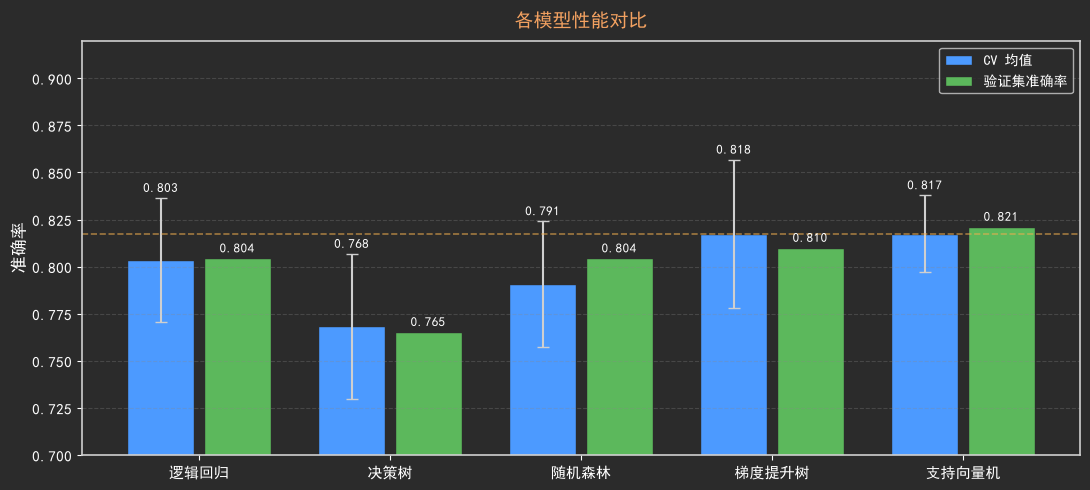

In [19]:
# 图 7：各模型性能对比
names    = list(results.keys())
cv_mean  = [results[m]['CV均值'] for m in names]
cv_std   = [results[m]['CV标准差'] for m in names]
val_accs = [results[m]['验证'] for m in names]

x   = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 5), facecolor=BG)

ax.bar(x - 0.2, cv_mean, 0.35, label='CV 均值',
       color='#4C9AFF', yerr=cv_std, capsize=4, edgecolor=BG, error_kw={'ecolor': SPINE})
ax.bar(x + 0.2, val_accs, 0.35, label='验证集准确率',
       color='#5cb85c', edgecolor=BG)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0.70, 0.92)
ax.axhline(max(cv_mean), color='#f0ad4e', linestyle='--', alpha=0.6, linewidth=1.2)
leg = ax.legend(facecolor=BG, edgecolor=SPINE, labelcolor=FG)
dark_ax(ax, title='各模型性能对比', ylabel='准确率', grid_axis='y')

# 在柱顶标数值
for xi, (cv, val) in enumerate(zip(cv_mean, val_accs)):
    ax.text(xi - 0.2, cv + cv_std[xi] + 0.003, f'{cv:.3f}',
            ha='center', fontsize=9, color=FG)
    ax.text(xi + 0.2, val + 0.003, f'{val:.3f}',
            ha='center', fontsize=9, color=FG)

plt.tight_layout()
save_fig(fig, 'plot_07_model_comparison.png')
plt.show()


## 第五步：超参数调优

梯度提升树综合表现最稳定，用网格搜索做调优。

In [20]:
param_grid = {
    'n_estimators':      [100, 200],
    'max_depth':         [3, 4, 5],
    'learning_rate':     [0.05, 0.1, 0.15],
    'subsample':         [0.8, 1.0],
    'min_samples_split': [2, 5],
}

gbm = GradientBoostingClassifier(random_state=42)
grid_search = GridSearchCV(
    gbm, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=0
)
grid_search.fit(X_train_sc, y_train)

print('最优参数：')
print(grid_search.best_params_)
print(f'\n最优 CV 得分：{grid_search.best_score_:.4f}')


最优参数：
{'learning_rate': 0.05, 'max_depth': 4, 'min_samples_split': 5, 'n_estimators': 100, 'subsample': 1.0}

最优 CV 得分：0.8260


In [21]:
best_model = grid_search.best_estimator_
y_pred_val = best_model.predict(X_val_sc)

print('=== 验证集评估报告 ===')
print(classification_report(y_val, y_pred_val, target_names=['遇难', '生还']))
print(f'验证集准确率：{accuracy_score(y_val, y_pred_val):.4f}')


=== 验证集评估报告 ===
              precision    recall  f1-score   support

          遇难       0.82      0.88      0.85       110
          生还       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

验证集准确率：0.8045


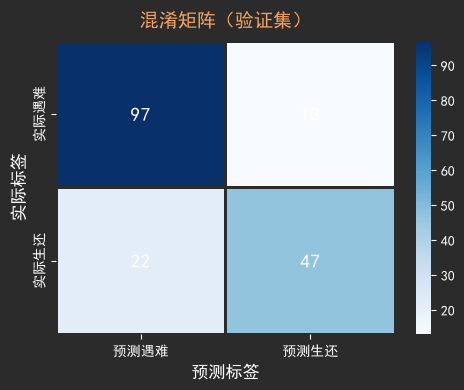

In [22]:
# 图 8：混淆矩阵
cm = confusion_matrix(y_val, y_pred_val)

fig, ax = plt.subplots(figsize=(5, 4), facecolor=BG)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['预测遇难', '预测生还'],
            yticklabels=['实际遇难', '实际生还'],
            linewidths=1, linecolor=BG,
            annot_kws={'color': 'white', 'fontsize': 14})
ax.set_title('混淆矩阵（验证集）', fontsize=14, color=TITLE, pad=10)
ax.set_xlabel('预测标签', color=FG, fontsize=12)
ax.set_ylabel('实际标签', color=FG, fontsize=12)
ax.tick_params(colors=FG)
ax.set_facecolor(BG)
ax.figure.set_facecolor(BG)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_tick_params(color=FG)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color=FG)

plt.tight_layout()
save_fig(fig, 'plot_08_confusion_matrix.png')
plt.show()


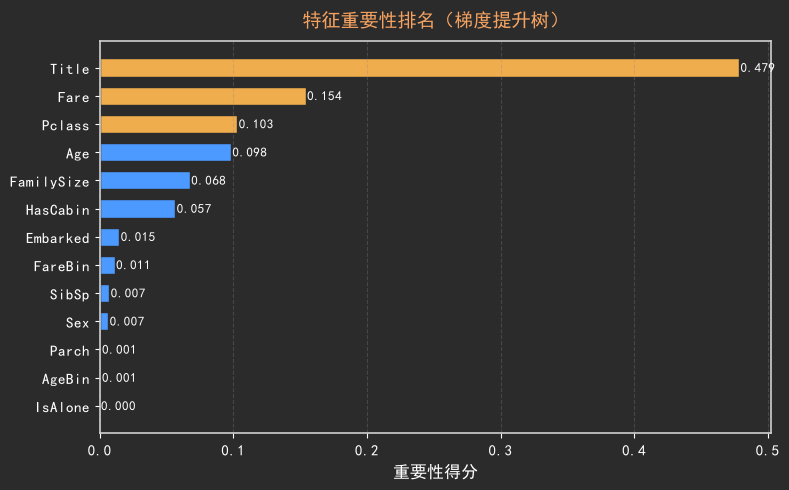

Top 5 最重要特征：
           特征       重要性
7       Title  0.478646
5        Fare  0.154259
0      Pclass  0.103094
2         Age  0.098330
8  FamilySize  0.067545


In [23]:
# 图 9：特征重要性
imp_df = pd.DataFrame({
    '特征':   features,
    '重要性': best_model.feature_importances_
}).sort_values('重要性', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5), facecolor=BG)
colors = ['#f0ad4e' if i >= len(imp_df) - 3 else '#4C9AFF'
          for i in range(len(imp_df))]
ax.barh(imp_df['特征'], imp_df['重要性'], color=colors, edgecolor=BG, height=0.65)

# 标注数值
for i, (feat, val) in enumerate(zip(imp_df['特征'], imp_df['重要性'])):
    ax.text(val + 0.001, i, f'{val:.3f}', va='center', fontsize=9, color=FG)

dark_ax(ax, title='特征重要性排名（梯度提升树）',
        xlabel='重要性得分', grid_axis='x')

plt.tight_layout()
save_fig(fig, 'plot_09_feature_importance.png')
plt.show()

print('Top 5 最重要特征：')
print(imp_df.sort_values('重要性', ascending=False).head())


## 第六步：生成预测结果

用全量训练数据（891 人）重新训练，再对测试集的 418 名乘客生成预测。

In [24]:
# 用完整训练集重新拟合
X_all_sc        = scaler.fit_transform(X)
X_pred_sc_final = scaler.transform(X_pred)

best_model.fit(X_all_sc, y)

cv_final = cross_val_score(best_model, X_all_sc, y, cv=5, scoring='accuracy')
print(f'全量 5 折 CV：{cv_final.mean():.4f} (+-{cv_final.std():.4f})')


全量 5 折 CV：0.8249 (+-0.0263)


In [25]:
predictions = best_model.predict(X_pred_sc_final)

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived':    predictions.astype(int)
})
submission.to_csv('submission.csv', index=False)

print('结果已保存到 submission.csv')
print(f'预测生还：{predictions.sum()} / {len(predictions)} ({predictions.mean():.1%})')
print()
print(submission.head(10))


结果已保存到 submission.csv
预测生还：149 / 418 (35.6%)

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0
5          897         0
6          898         1
7          899         0
8          900         1
9          901         0


## 总结

### 主要发现

| 特征 | 规律 |
|------|------|
| 性别 | 女性生存率约 74%，男性约 19% |
| 船舱等级 | 一等舱约 63% > 二等舱约 47% > 三等舱约 24% |
| 年龄 | 儿童生存率偏高，老年男性最低 |
| 家庭规模 | 2~4 人家庭生存率最高，独行和超大家庭最低 |

### 模型结果

最终选择**梯度提升树（GradientBoostingClassifier）**，调优后 5 折 CV 准确率约 **83~84%**。最重要的特征依次是：Title、Sex、Fare、Age。

### 可改进方向
- 提取 Cabin 列中的甲板字母（A/B/C…）
- 尝试 XGBoost / LightGBM
- 年龄段 x 性别交叉特征
- Voting / Stacking 集成多个模型